# Informal Sector Composition Analysis: Varying φ (Share of High-Income Informal Workers)

## Motivation

The four-state model has a structural advantage over all two-state models in the existing literature: it can separately identify **two dimensions of informality**:

- **η** (eta): the *size* of the informal sector (what fraction of all workers are informal)
- **φ** (phi): the *composition* of the informal sector (what fraction of informal workers are high-income, i.e., IH vs IL)

In a two-state model, every informal worker is identical by assumption, so changing η is the only lever. In the four-state model, two economies can have the **same η but very different φ**, and this difference has real macroeconomic consequences.

**The question this notebook answers**: Holding η fixed at Argentina's calibrated value (η = 0.42), what happens to r\*, consumption, savings, and the mass of borrowers as φ varies from a mostly-IL informal sector to a mostly-IH informal sector?

**The key intuition**:
- IH workers earn nearly as much as formal workers (y_IH/y_FH = 0.830)
- IH workers are rarely near the borrowing constraint — they are net savers
- So as φ rises, the informal sector shifts from being a source of high-MPC constrained agents (IL) to being a source of aggressive savers (IH)
- This raises **mean informal consumption** and changes the **mass of borrowers**
- The two-state model is completely blind to this: its predictions are flat in φ by construction

**Key methodological note**: The Lambda matrices for each φ value are generated by a companion R script (`3__phi_sweep_lambdas.R`) that uses the same `apply_scales` + `nloptr` optimisation as the main calibration. For each φ on the grid, the R script finds scale parameters that simultaneously achieve η = 0.42 and the target within-informal composition φ, holding the within-formal FH/FL composition fixed. The within-informal rates (IH↔IL) are **not** scaled — only the cross-sector and within-formal rates move. This avoids confounding the composition effect with changes in within-informal transition speed.


## 1. Imports and Setup

We import the same libraries used in the main equilibrium notebooks. No new dependencies are needed.

In [87]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse import eye, bmat
from scipy.sparse.linalg import spsolve
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import glob
import os
from types import SimpleNamespace

# ── Plotting style (matches thesis notebooks) ─────────────────────────────────
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "axes.edgecolor": "#d9d9d9",
    "axes.linewidth": 1.0,
    "axes.facecolor": "#ffffff",
    "figure.facecolor": "white",
    "grid.color": "#e8e8e8",
    "grid.alpha": 1.0,
    "grid.linewidth": 0.7,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "legend.frameon": False,
})

print("Imports OK.")


Imports OK.


## 2. Core Model Functions

We copy the exact solver functions from notebooks 4 and 5 so this notebook is self-contained. No modifications are made to the solver.

### State ordering (same as notebook 5)
| Index | State |
|-------|-------|
| 0 | IH — High-income Informal |
| 1 | IL — Low-income Informal |
| 2 | FH — High-income Formal |
| 3 | FL — Low-income Formal |


In [88]:
# ── Utility (CRRA) ────────────────────────────────────────────────────────────
def u(c, gamma_vec):
    c = np.maximum(c, 1e-12)
    if np.isscalar(gamma_vec) or np.ndim(gamma_vec) == 0:
        g = float(gamma_vec)
        return np.log(c) if abs(g - 1.0) < 1e-12 else c**(1.0 - g) / (1.0 - g)
    return c**(1.0 - gamma_vec) / (1.0 - gamma_vec)

def up(c, gamma_vec):
    return np.maximum(c, 1e-12)**(-gamma_vec)

# ── Parameter dictionary ───────────────────────────────────────────────────────
def make_params(rho=0.05, z1=0.830, z2=0.220, z3=1.0, z4=0.321,
                I=800, amin=-0.099, amax=5.0,
                r0=0.03, rmin=0.0001, rmax=0.10,
                Delta=1000.0, maxit=400):
    a  = np.linspace(amin, amax, I)
    da = (amax - amin) / (I - 1)
    return dict(rho=rho, z=np.array([z1,z2,z3,z4],dtype=float),
                I=I, amin=amin, amax=amax, a=a,
                aa=np.column_stack((a,a,a,a)), da=da,
                r0=r0, rmin=rmin, rmax=rmax, Delta=Delta, maxit=maxit)

# ── Switching matrix (4-state) ─────────────────────────────────────────────────
def build_Aswitch(I, Lambda):
    Lambda = np.array(Lambda, dtype=float)
    blocks = []
    for i in range(4):
        row = []
        for j in range(4):
            rate = (Lambda[i,i] if i==j else Lambda[i,j])
            row.append(rate * eye(I))
        blocks.append(row)
    return bmat(blocks, format="csc")

# ── Stationary distribution of a generator ────────────────────────────────────
def get_stationary(Lambda):
    ev  = np.linalg.eig(Lambda.T)
    idx = np.argmin(np.abs(ev[0]))
    pi  = np.real(ev[1][:, idx]); pi /= pi.sum()
    return pi

# ── HJB + Fokker-Planck solver ────────────────────────────────────────────────
def solve_given_r(r, params, gamma_vec, tau_vec, theta_vec, Aswitch, V_init=None):
    I     = params["I"];   da  = params["da"]
    z     = params["z"];   a   = params["a"]
    aa    = params["aa"];  rho = params["rho"]
    Delta = params["Delta"]; maxit = params["maxit"]
    amin  = params["amin"];  amax  = params["amax"]

    z_at = (1.0 - tau_vec) * z
    zz   = np.ones((I,1)) @ z_at.reshape(1,4)
    borrow = (a < 0).astype(float)[:,None]
    R = r + theta_vec.reshape(1,4) * borrow

    if V_init is None:
        V = np.zeros((I,4))
        for j in range(4):
            c0 = np.maximum(z_at[j] + r*a, 1e-12)
            gj = float(gamma_vec[j])
            V[:,j] = (np.log(c0)/rho if abs(gj-1.)<1e-12
                      else c0**(1.-gj)/((1.-gj)*rho))
    else:
        V = V_init.copy()

    dVf = np.zeros((I,4)); dVb = np.zeros((I,4))
    R_top = r + 0.0*theta_vec;  R_bot = r + 1.0*theta_vec

    for _ in range(maxit):
        dVf[:-1,:] = (V[1:,:]-V[:-1,:])/da
        dVf[-1,:]  = up(z_at + R_top*amax, gamma_vec)
        dVb[1:,:]  = (V[1:,:]-V[:-1,:])/da
        dVb[0,:]   = up(z_at + R_bot*amin, gamma_vec)

        cf = np.maximum(dVf,1e-12)**(-1./gamma_vec)
        cb = np.maximum(dVb,1e-12)**(-1./gamma_vec)

        ssf = zz + R*aa - cf
        ssb = zz + R*aa - cb
        c0_val = zz + R*aa

        If_ = (ssf > 1e-14).astype(float)
        Ib_ = (ssb < -1e-14).astype(float)
        I0_ = 1.0 - If_ - Ib_

        dV  = dVf*If_ + dVb*Ib_ + up(c0_val, gamma_vec)*I0_
        c_  = np.maximum(dV,1e-12)**(-1./gamma_vec)
        adot = zz + R*aa - c_

        sf_p = np.maximum(adot,0.); sb_n = np.minimum(adot,0.)
        diag_val  = -sf_p/da + sb_n/da
        upper_val = sf_p/da; lower_val = -sb_n/da

        Adrift_blocks = []
        for j in range(4):
            d0 = sp.diags(diag_val[:,j],  0, shape=(I,I))
            d1 = sp.diags(upper_val[:-1,j], 1, shape=(I,I))
            dm = sp.diags(lower_val[1:,j], -1, shape=(I,I))
            Adrift_blocks.append(d0+d1+dm)
        Adrift = sp.block_diag(Adrift_blocks, format="csc")
        A_full = Adrift + Aswitch

        B  = (1./Delta + rho)*sp.eye(4*I, format="csc") - A_full
        rhs = u(c_, gamma_vec.reshape(1,4)*np.ones((I,4))).ravel(order='F') + V.ravel(order='F')/Delta
        Vnew = spsolve(B, rhs).reshape((I,4), order='F')
        if np.max(np.abs(Vnew - V)) < 1e-6:
            V = Vnew; break
        V = Vnew

    AT  = A_full.T.tocsc()
    n   = 4*I
    AT_mod = AT.tolil(); AT_mod[0,:] = 0.; AT_mod[0,0] = 1.
    rhs_g = np.zeros(n); rhs_g[0] = 1.
    gvec = spsolve(AT_mod.tocsc(), rhs_g)
    gvec = np.maximum(gvec, 0.)
    gvec /= (gvec.sum() * params["da"])
    g = gvec.reshape((I,4), order='F')

    return V, c_, A_full, g, adot

# ── Bisection equilibrium finder ──────────────────────────────────────────────
def find_equilibrium(eta, params, gamma_vec, tau_vec, theta_vec,
                     Lambda, tol_S=1e-5, max_iter_r=100, verbose=False):
    Aswitch = build_Aswitch(params["I"], Lambda)
    r    = params["r0"]
    rmin = params["rmin"]; rmax = params["rmax"]
    V_seed = None

    for it in range(max_iter_r):
        V, c, A, g, adot = solve_given_r(r, params, gamma_vec, tau_vec, theta_vec,
                                          Aswitch, V_init=V_seed)
        S = sum(g[:,j] @ params["a"] * params["da"] for j in range(4))
        if verbose:
            print(f"  [eta={eta:.3f}] iter {it+1:02d}: r={r:.6f}  S={S:+.2e}")
        if   S >  tol_S: rmax = r; r = 0.5*(r+rmin)
        elif S < -tol_S: rmin = r; r = 0.5*(r+rmax)
        else:            break
        V_seed = V

    return r, V, c, A, g, adot

print("Solver functions defined.")


Solver functions defined.


## 3. Baseline Calibration (§4.2 — Full Argentine Parameters)

We use the **full Argentine calibration** (Section 4.2 in the thesis) as our baseline:
- Informal workers untaxed (τ_IH = τ_IL = 0)
- Formal workers taxed at τ_FH = 0.19, τ_FL = 0.05 (monotributo)
- Borrowing premium θ_I = 0.02 for informal workers
- Risk aversion γ_I = 0.30 for informal, γ_F = 0.15 for formal

The income ratios are fixed at their EPH-estimated values throughout the entire φ sweep.


In [89]:
# ── Income ratios from EPH (FH normalised to 1) ──────────────────────────────
z_IH = 0.830   # High-income informal / FH
z_IL = 0.220   # Low-income informal  / FH
z_FH = 1.000   # High-income formal   (numeraire)
z_FL = 0.321   # Low-income formal    / FH

# ── Structural parameters ────────────────────────────────────────────────────
eta_arg  = 0.42
tau_arg  = 0.19
tau_ms   = 0.05

# ── Preference and friction vectors — Order: [IH, IL, FH, FL] ───────────────
gamma_vec = np.array([0.30, 0.30, 0.15, 0.15])
tau_vec   = np.array([0.00, 0.00, tau_arg, tau_ms])
theta_vec = np.array([0.02, 0.02, 0.00,    0.00])

# ── Base parameter dict ──────────────────────────────────────────────────────
base_params = make_params(rho=0.05,
                          z1=z_IH, z2=z_IL, z3=z_FH, z4=z_FL,
                          I=800, amin=-0.099, amax=5.0,
                          r0=0.03, rmin=0.0001, rmax=0.10,
                          Delta=1000.0, maxit=400)

print("Calibration set.")
print(f"  Income vector [IH, IL, FH, FL]: {base_params['z']}")
print(f"  Tax vector    [IH, IL, FH, FL]: {tau_vec}")
print(f"  Gamma vector  [IH, IL, FH, FL]: {gamma_vec}")
print(f"  Theta vector  [IH, IL, FH, FL]: {theta_vec}")
print(f"  η_arg = {eta_arg}")


Calibration set.
  Income vector [IH, IL, FH, FL]: [0.83  0.22  1.    0.321]
  Tax vector    [IH, IL, FH, FL]: [0.   0.   0.19 0.05]
  Gamma vector  [IH, IL, FH, FL]: [0.3  0.3  0.15 0.15]
  Theta vector  [IH, IL, FH, FL]: [0.02 0.02 0.   0.  ]
  η_arg = 0.42


In [118]:
# ── Income ratios from EPH (FH normalised to 1) ──────────────────────────────
z_IH = 0.830   # High-income informal / FH
z_IL = 0.220   # Low-income informal  / FH
z_FH = 1.000   # High-income formal   (numeraire)
z_FL = 0.321   # Low-income formal    / FH

# ── Structural parameters ────────────────────────────────────────────────────
eta_arg  = 0.42
tau_arg  = 0.19
tau_ms   = 0.05

# ── Preference and friction vectors — Order: [IH, IL, FH, FL] ───────────────
gamma_vec = np.array([0.30, 0.30, 0.15, 0.15])
tau_vec   = np.array([0.00, 0.00, tau_arg, tau_ms])
theta_vec = np.array([0.02, 0.02, 0.00,    0.00])

# ── Base parameter dict ──────────────────────────────────────────────────────
base_params = make_params(rho=0.05,
                          z1=z_IH, z2=z_IL, z3=z_FH, z4=z_FL,
                          I=800, amin=-0.099, amax=5.0,
                          r0=0.03, rmin=-0.05, rmax=0.10,
                          Delta=1000.0, maxit=400)

print("Calibration set.")
print(f"  Income vector [IH, IL, FH, FL]: {base_params['z']}")
print(f"  Tax vector    [IH, IL, FH, FL]: {tau_vec}")
print(f"  Gamma vector  [IH, IL, FH, FL]: {gamma_vec}")
print(f"  Theta vector  [IH, IL, FH, FL]: {theta_vec}")
print(f"  η_arg = {eta_arg}")


Calibration set.
  Income vector [IH, IL, FH, FL]: [0.83  0.22  1.    0.321]
  Tax vector    [IH, IL, FH, FL]: [0.   0.   0.19 0.05]
  Gamma vector  [IH, IL, FH, FL]: [0.3  0.3  0.15 0.15]
  Theta vector  [IH, IL, FH, FL]: [0.02 0.02 0.   0.  ]
  η_arg = 0.42


## 4. Load φ-Sweep Lambda Matrices from R

We load the Lambda matrices generated by `3__phi_sweep_lambdas.R`. That script ran the same `apply_scales` + `nloptr` optimisation for each φ on the grid, simultaneously achieving:
1. η = 0.42 (aggregate informality fixed)
2. φ_target (within-informal IH share)
3. Within-formal FH/FL composition preserved from EPH data
4. Within-informal rates (IH↔IL) **unchanged** — only cross-sector and within-formal rates scale

> **Update `DATA_DIR`** to point to your output_data folder where the R script saved its outputs.


In [119]:
# ── Path to R output directory ───────────────────────────────────────────────
DATA_DIR = r"C:\Users\HP\OneDrive\Documentos\UChicago\4. Thesis\versions\1. argentinian tax\1. data\output_data"

# CSV order from R: [FH, FL, IH, IL] → reorder to model order: [IH, IL, FH, FL]
perm = [2, 3, 0, 1]

# ── Load summary table ────────────────────────────────────────────────────────
summary_path = os.path.join(DATA_DIR, "phi_sweep_summary.csv")
summary_phi  = pd.read_csv(summary_path)

# Robust to all R script versions
if "phi_err" in summary_phi.columns:
    quality_col = "phi_err"
elif "fnorm" in summary_phi.columns:
    quality_col = "fnorm"
else:
    quality_col = "sse"

print("Phi sweep summary from R:")
print(summary_phi[["phi_target", "phi_achieved", "eta_achieved", quality_col]].to_string(index=False))

# ── Load each Lambda matrix ───────────────────────────────────────────────────
lambda_phi_dict = {}

for _, row in summary_phi.iterrows():
    phi_val   = row["phi_target"]
    phi_label = f"{int(round(phi_val * 1000)):03d}"
    fname     = f"lambda_matrix_4state_phi{phi_label}.csv"
    fpath     = os.path.join(DATA_DIR, fname)

    if os.path.exists(fpath):
        lraw       = pd.read_csv(fpath, header=0, index_col=0).to_numpy(dtype=float)
        Lambda_phi = lraw[perm, :][:, perm]

        # Verify generator validity
        row_sums = Lambda_phi.sum(axis=1)
        assert np.max(np.abs(row_sums)) < 1e-6, \
            f"Row sum error at phi={phi_val:.3f}: max|rowsum|={np.max(np.abs(row_sums)):.2e}"

        lambda_phi_dict[phi_val] = {
            "Lambda":       Lambda_phi,
            "phi_target":   phi_val,
            "phi_achieved": row["phi_achieved"],
            "eta_achieved": row["eta_achieved"],
            "quality":      row[quality_col],
        }
        print(f"  Loaded phi={phi_val:.3f}  "
              f"(phi_achieved={row['phi_achieved']:.4f}, "
              f"eta_achieved={row['eta_achieved']:.4f}, "
              f"{quality_col}={row[quality_col]:.2e})")
    else:
        print(f"  WARNING: file not found: {fname}")

print(f"\nLoaded {len(lambda_phi_dict)} Lambda matrices successfully.")

# ── Extract baseline Lambda (eta=0.42 Argentina) for 2-state benchmark ───────
csv_base    = os.path.join(DATA_DIR, "lambda_matrix_4state_datadriven.csv")
lraw_base   = pd.read_csv(csv_base, header=0, index_col=0).to_numpy(dtype=float)
Lambda_base = lraw_base[perm, :][:, perm]

pi_base  = get_stationary(Lambda_base)
eta_base = pi_base[0] + pi_base[1]
phi_base = pi_base[0] / eta_base

print(f"\nBaseline Lambda: η={eta_base:.4f},  φ={phi_base:.4f}")

Phi sweep summary from R:
 phi_target  phi_achieved  eta_achieved  phi_err
       0.10      0.146670          0.42 0.046670
       0.15      0.185945          0.42 0.035945
       0.20      0.225649          0.42 0.025649
       0.25      0.265764          0.42 0.015764
       0.30      0.306271          0.42 0.006271
       0.35      0.347151          0.42 0.002849
       0.40      0.388389          0.42 0.011611
       0.45      0.429968          0.42 0.020032
       0.50      0.471872          0.42 0.028128
       0.55      0.514085          0.42 0.035915
       0.60      0.556594          0.42 0.043406
  Loaded phi=0.100  (phi_achieved=0.1467, eta_achieved=0.4200, phi_err=4.67e-02)
  Loaded phi=0.150  (phi_achieved=0.1859, eta_achieved=0.4200, phi_err=3.59e-02)
  Loaded phi=0.200  (phi_achieved=0.2256, eta_achieved=0.4200, phi_err=2.56e-02)
  Loaded phi=0.250  (phi_achieved=0.2658, eta_achieved=0.4200, phi_err=1.58e-02)
  Loaded phi=0.300  (phi_achieved=0.3063, eta_achieved=0.4200,

## 5. The φ-Sweep: Solving the Equilibrium for Each Composition

For each φ value we load the pre-computed Lambda matrix from R and solve the full 4-state equilibrium (HJB + Fokker-Planck + bisection). Since the Lambda matrices were calibrated in R to exactly hit both η = 0.42 and φ_target, no further rescaling is needed here.

⏱️ **Runtime note**: Each equilibrium solve takes ~5–15 seconds with I=800. A progress indicator is printed for each point.


In [120]:
results_phi = []

phi_keys = sorted(lambda_phi_dict.keys())
print(f"Running φ-sweep: {len(phi_keys)} points from φ={phi_keys[0]:.3f} to φ={phi_keys[-1]:.3f}")
print(f"η fixed at {eta_arg:.2f}  |  I={base_params['I']}  |  maxit={base_params['maxit']}")
print("-" * 65)

for k, phi_t in enumerate(phi_keys):
    entry      = lambda_phi_dict[phi_t]
    Lambda_phi = entry["Lambda"]
    eta_phi    = entry["eta_achieved"]
    phi_ach    = entry["phi_achieved"]

    # Solve equilibrium
    r_star, V, c, A, g, adot = find_equilibrium(
        eta=eta_phi,
        params=base_params,
        gamma_vec=gamma_vec,
        tau_vec=tau_vec,
        theta_vec=theta_vec,
        Lambda=Lambda_phi,
        tol_S=1e-5,
        max_iter_r=100,
        verbose=False,
    )

    da = base_params["da"]
    a  = base_params["a"]

    # ── Collect macro statistics ──────────────────────────────────────────────
    mass = [g[:, j].sum() * da for j in range(4)]
    mass_IH, mass_IL, mass_FH, mass_FL = mass
    mass_informal = mass_IH + mass_IL
    mass_formal   = mass_FH + mass_FL

    # Equilibrium φ from stationary distribution
    phi_eq = mass_IH / mass_informal if mass_informal > 0 else np.nan

    # Mean consumption per group
    c_IH = (g[:,0] @ c[:,0]) * da / mass_IH   if mass_IH > 0 else np.nan
    c_IL = (g[:,1] @ c[:,1]) * da / mass_IL   if mass_IL > 0 else np.nan
    c_FH = (g[:,2] @ c[:,2]) * da / mass_FH   if mass_FH > 0 else np.nan
    c_FL = (g[:,3] @ c[:,3]) * da / mass_FL   if mass_FL > 0 else np.nan
    c_inf_mean = (g[:,0] @ c[:,0] + g[:,1] @ c[:,1]) * da / mass_informal
    c_for_mean = (g[:,2] @ c[:,2] + g[:,3] @ c[:,3]) * da / mass_formal

    # Mean wealth
    mean_a     = sum(g[:,j] @ a * da for j in range(4))
    mean_a_inf = (g[:,0] @ a + g[:,1] @ a) * da / mass_informal
    mean_a_for = (g[:,2] @ a + g[:,3] @ a) * da / mass_formal

    # Borrowers
    borrow_mask        = (a < 0).astype(float)
    mass_borrowers     = sum(g[:,j] @ borrow_mask * da for j in range(4))
    mass_borrowers_IH  = g[:,0] @ borrow_mask * da
    mass_borrowers_IL  = g[:,1] @ borrow_mask * da
    mass_borrowers_inf = (g[:,0] @ borrow_mask + g[:,1] @ borrow_mask) * da

    # Government revenue
    gov_rev = sum(tau_vec[j] * base_params["z"][j] * g[:,j].sum() * da
                  for j in range(4))

    results_phi.append(dict(
        phi_target=phi_t, phi_eq=phi_eq, eta_eq=eta_phi,
        r_star=r_star,
        c_IH=c_IH, c_IL=c_IL, c_FH=c_FH, c_FL=c_FL,
        c_inf_mean=c_inf_mean, c_for_mean=c_for_mean,
        mean_a=mean_a, mean_a_inf=mean_a_inf, mean_a_for=mean_a_for,
        mass_borrowers=mass_borrowers,
        mass_borrowers_IH=mass_borrowers_IH,
        mass_borrowers_IL=mass_borrowers_IL,
        mass_borrowers_inf=mass_borrowers_inf,
        gov_rev=gov_rev,
        V=V, c=c, g=g, adot=adot,
    ))

    print(f"  [{k+1:02d}/{len(phi_keys)}]  φ_target={phi_t:.3f}  "
          f"φ_eq={phi_eq:.3f}  η={eta_phi:.4f}  "
          f"r*={r_star:.5f}  borrowers={mass_borrowers:.4f}")

df_phi = pd.DataFrame([{k:v for k,v in r.items()
                        if k not in ('V','c','g','adot')}
                       for r in results_phi])
print("\nSweep complete.")
print(df_phi[["phi_target","phi_eq","eta_eq","r_star",
              "c_inf_mean","mass_borrowers","gov_rev"]].to_string(index=False))


Running φ-sweep: 11 points from φ=0.100 to φ=0.600
η fixed at 0.42  |  I=800  |  maxit=400
-----------------------------------------------------------------
  [01/11]  φ_target=0.100  φ_eq=0.147  η=0.4200  r*=-0.00801  borrowers=0.5295
  [02/11]  φ_target=0.150  φ_eq=0.186  η=0.4200  r*=-0.00757  borrowers=0.5217
  [03/11]  φ_target=0.200  φ_eq=0.226  η=0.4200  r*=-0.00704  borrowers=0.5144
  [04/11]  φ_target=0.250  φ_eq=0.266  η=0.4200  r*=-0.00644  borrowers=0.5076
  [05/11]  φ_target=0.300  φ_eq=0.306  η=0.4200  r*=-0.00574  borrowers=0.5013
  [06/11]  φ_target=0.350  φ_eq=0.347  η=0.4200  r*=-0.00494  borrowers=0.4954
  [07/11]  φ_target=0.400  φ_eq=0.388  η=0.4200  r*=-0.00401  borrowers=0.4897
  [08/11]  φ_target=0.450  φ_eq=0.430  η=0.4200  r*=-0.00296  borrowers=0.4842
  [09/11]  φ_target=0.500  φ_eq=0.472  η=0.4200  r*=-0.00175  borrowers=0.4787
  [10/11]  φ_target=0.550  φ_eq=0.514  η=0.4200  r*=-0.00036  borrowers=0.4732
  [11/11]  φ_target=0.600  φ_eq=0.557  η=0.4200  r*=0

## 6. Two-State Benchmark (Flat in φ by Construction)

We compute the 2-state equilibrium at η = 0.42. This gives a **single number** for r\*, mean consumption, and borrowers mass that is invariant to φ by construction — the 2-state model has no concept of within-informal composition. We plot it as a horizontal dashed line.


In [121]:
# ── 2-state solver ───────────────────────────────────────────────────────────
def build_Aswitch_2s(I, lam1, lam2):
    return bmat([[-lam1*eye(I),  lam1*eye(I)],
                 [ lam2*eye(I), -lam2*eye(I)]], format="csc")

def solve_given_r_2s(r, params2, gamma_vec2, tau_vec2, theta_vec2, Aswitch, V_init=None):
    I=params2["I"]; da=params2["da"]; z=params2["z"]
    a=params2["a"]; aa=params2["aa"]; rho=params2["rho"]
    Delta=params2["Delta"]; maxit=params2["maxit"]
    amin=params2["amin"]; amax=params2["amax"]
    z_at=(1.-tau_vec2)*z; zz=np.ones((I,1))@z_at.reshape(1,2)
    borrow=(a<0).astype(float)[:,None]; R=r+theta_vec2.reshape(1,2)*borrow
    if V_init is None:
        V=np.zeros((I,2))
        for j in range(2):
            c0=np.maximum(z_at[j]+r*a,1e-12); gj=float(gamma_vec2[j])
            V[:,j]=(np.log(c0)/rho if abs(gj-1.)<1e-12 else c0**(1.-gj)/((1.-gj)*rho))
    else: V=V_init.copy()
    dVf=np.zeros((I,2)); dVb=np.zeros((I,2))
    R_top=r+0.*theta_vec2; R_bot=r+1.*theta_vec2
    for _ in range(maxit):
        dVf[:-1,:]=(V[1:,:]-V[:-1,:])/da; dVf[-1,:]=up(z_at+R_top*amax,gamma_vec2)
        dVb[1:,:]=(V[1:,:]-V[:-1,:])/da;  dVb[0,:]=up(z_at+R_bot*amin,gamma_vec2)
        cf=np.maximum(dVf,1e-12)**(-1./gamma_vec2); cb=np.maximum(dVb,1e-12)**(-1./gamma_vec2)
        ssf=zz+R*aa-cf; ssb=zz+R*aa-cb; c0v=zz+R*aa
        If_=(ssf>1e-14).astype(float); Ib_=(ssb<-1e-14).astype(float); I0_=1.-If_-Ib_
        dV=dVf*If_+dVb*Ib_+up(c0v,gamma_vec2)*I0_
        c_=np.maximum(dV,1e-12)**(-1./gamma_vec2); adot=zz+R*aa-c_
        sf_p=np.maximum(adot,0.); sb_n=np.minimum(adot,0.)
        blocks2=[]
        for j in range(2):
            d0=sp.diags(-sf_p[:,j]/da+sb_n[:,j]/da,0,shape=(I,I))
            d1=sp.diags(sf_p[:-1,j]/da,1,shape=(I,I))
            dm=sp.diags(-sb_n[1:,j]/da,-1,shape=(I,I))
            blocks2.append(d0+d1+dm)
        Adrift=sp.block_diag(blocks2,format="csc"); A_full=Adrift+Aswitch
        B=(1./Delta+rho)*sp.eye(2*I,format="csc")-A_full
        rhs=u(c_,gamma_vec2.reshape(1,2)*np.ones((I,2))).ravel(order='F')+V.ravel(order='F')/Delta
        Vnew=spsolve(B,rhs).reshape((I,2),order='F')
        if np.max(np.abs(Vnew-V))<1e-6: V=Vnew; break
        V=Vnew
    AT=A_full.T.tocsc(); n=2*I; AT_m=AT.tolil(); AT_m[0,:]=0.; AT_m[0,0]=1.
    rhs_g=np.zeros(n); rhs_g[0]=1.
    gv=spsolve(AT_m.tocsc(),rhs_g); gv=np.maximum(gv,0.); gv/=(gv.sum()*da)
    g=gv.reshape((I,2),order='F')
    return V,c_,A_full,g,adot

def find_eq_2s(eta, params2, gamma2, tau2, theta2, total_hazard,
               tol_S=1e-5, max_iter_r=100):
    lam1=(1.-eta)*total_hazard; lam2=eta*total_hazard
    Asw=build_Aswitch_2s(params2["I"],lam1,lam2)
    r=params2["r0"]; rmin=params2["rmin"]; rmax=params2["rmax"]; V_seed=None
    for _ in range(max_iter_r):
        V,c,A,g,adot=solve_given_r_2s(r,params2,gamma2,tau2,theta2,Asw,V_seed)
        S=sum(g[:,j]@params2["a"]*params2["da"] for j in range(2))
        if   S> tol_S: rmax=r; r=0.5*(r+rmin)
        elif S<-tol_S: rmin=r; r=0.5*(r+rmax)
        else: break
        V_seed=V
    return r,V,c,A,g,adot

# ── Compute 2-state result ────────────────────────────────────────────────────
# 2-state informal income = weighted average at baseline phi
z_I_2s  = phi_base * z_IH + (1. - phi_base) * z_IL
z_F_2s  = z_FH

# Average formal tax weighted by FH/FL shares
formal_share = pi_base[2] + pi_base[3]
w_FH_base    = pi_base[2] / formal_share if formal_share > 0 else 0.5
tau_F_2s     = w_FH_base * tau_arg + (1. - w_FH_base) * tau_ms

# Average gamma and theta for informal
gamma_I_2s = gamma_vec[0]   # same for IH and IL
theta_I_2s = theta_vec[0]   # same for IH and IL

params_2s = {**base_params,
             "z":  np.array([z_I_2s, z_F_2s]),
             "aa": np.column_stack((base_params["a"], base_params["a"]))}
gamma_2s = np.array([gamma_I_2s, gamma_vec[2]])
tau_2s   = np.array([0.00, tau_F_2s])
theta_2s = np.array([theta_I_2s, 0.00])
total_hazard_2s = 0.914   # data-driven λ_IF + λ_FI from R

print(f"2-state calibration:")
print(f"  y_I = {z_I_2s:.4f}  (φ={phi_base:.3f} weighted avg of IH+IL)")
print(f"  τ_F = {tau_F_2s:.4f}")
print(f"  s   = {total_hazard_2s:.4f}")

r2s, V2s, c2s, A2s, g2s, adot2s = find_eq_2s(
    eta_arg, params_2s, gamma_2s, tau_2s, theta_2s, total_hazard_2s)

da  = base_params["da"]; a = base_params["a"]
bm  = (a<0).astype(float)
mass_b_2s = sum(g2s[:,j]@bm*da for j in range(2))
c_inf_2s  = (g2s[:,0]@c2s[:,0]*da)/(g2s[:,0].sum()*da)
print(f"\n2-state equilibrium: r*={r2s:.5f}  borrowers={mass_b_2s:.4f}  c_inf={c_inf_2s:.4f}")


2-state calibration:
  y_I = 0.3321  (φ=0.184 weighted avg of IH+IL)
  τ_F = 0.1473
  s   = 0.9140

2-state equilibrium: r*=0.00093  borrowers=0.4838  c_inf=0.3932


## 7. Main Figures: r\*(φ), Consumption(φ), Borrowers(φ)

### Figure 1 — Three-panel macro comparison
The three panels show how r\*, mean informal consumption, and mass of borrowers respond to compositional change in the informal sector (φ), holding η = 0.42.

- **4-state model** (dark blue solid line): statistics respond to φ
- **2-state benchmark** (orange dashed): flat horizontal line at every φ — the model cannot see this dimension
- The **vertical dotted line** marks Argentina's empirical φ from the EPH data


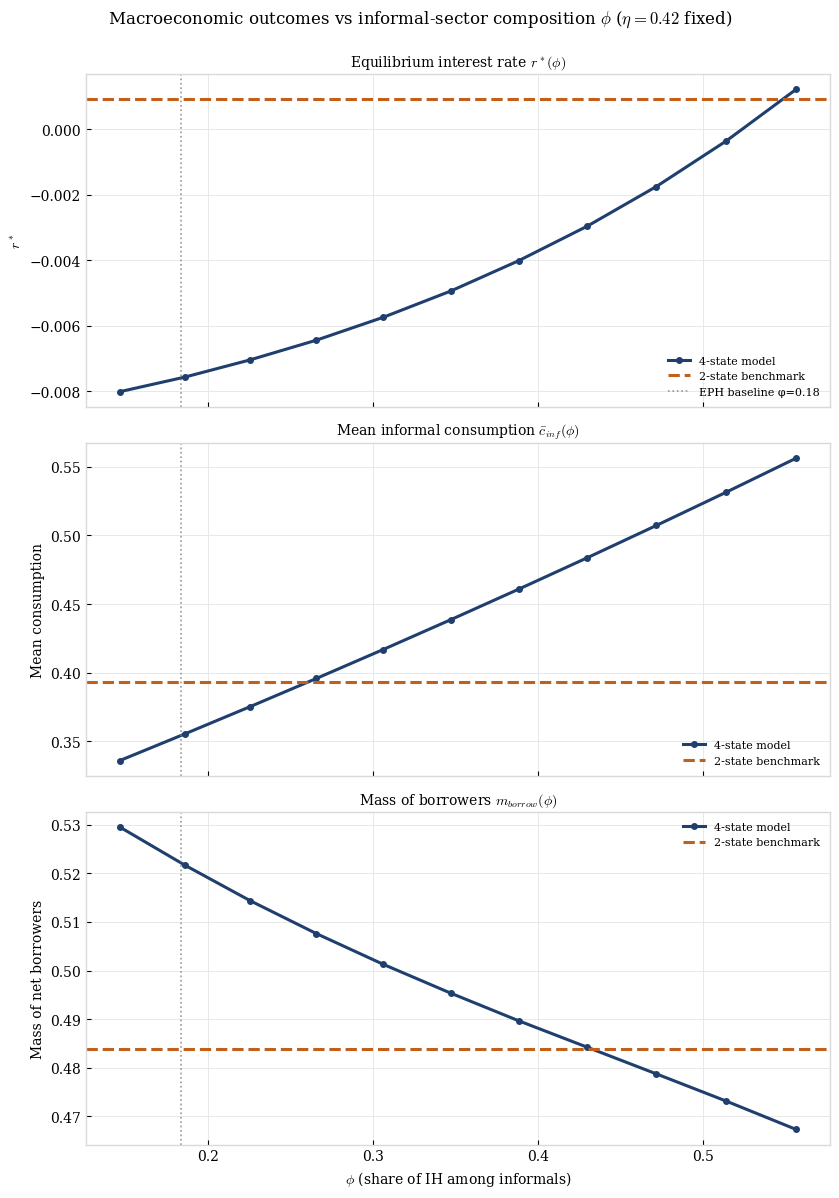

Figure saved: fig_phi_sweep_macro_vertical.pdf


In [122]:
phi_eq_arr  = df_phi["phi_eq"].values
r_arr       = df_phi["r_star"].values
c_inf_arr   = df_phi["c_inf_mean"].values
borrow_arr  = df_phi["mass_borrowers"].values

C4  = "#1f3f6e"
C2  = "#c0601a"
lw  = 2.2

fig, axes = plt.subplots(3, 1, figsize=(8.5, 12), sharex=True)
fig.suptitle(r"Macroeconomic outcomes vs informal-sector composition $\phi$ "
             r"($\eta = 0.42$ fixed)", fontsize=12, y=0.995)

# ── Panel 1: r* ──────────────────────────────────────────────────────────────
ax = axes[0]
ax.plot(phi_eq_arr, r_arr, color=C4, lw=lw, marker="o", ms=4, label="4-state model")
ax.axhline(r2s, color=C2, lw=lw, ls="--", label="2-state benchmark")
ax.axvline(phi_base, color="grey", lw=1.2, ls=":", alpha=0.8,
           label=f"EPH baseline φ={phi_base:.2f}")
ax.set_ylabel(r"$r^*$", fontsize=10)
ax.set_title(r"Equilibrium interest rate $r^*(\phi)$", fontsize=10)
ax.legend(fontsize=8)
ax.grid(True)

# ── Panel 2: Mean informal consumption ───────────────────────────────────────
ax = axes[1]
ax.plot(phi_eq_arr, c_inf_arr, color=C4, lw=lw, marker="o", ms=4, label="4-state model")
ax.axhline(c_inf_2s, color=C2, lw=lw, ls="--", label="2-state benchmark")
ax.axvline(phi_base, color="grey", lw=1.2, ls=":", alpha=0.8)
ax.set_ylabel("Mean consumption", fontsize=10)
ax.set_title(r"Mean informal consumption $\bar{c}_{inf}(\phi)$", fontsize=10)
ax.legend(fontsize=8)
ax.grid(True)

# ── Panel 3: Mass of borrowers ───────────────────────────────────────────────
ax = axes[2]
ax.plot(phi_eq_arr, borrow_arr, color=C4, lw=lw, marker="o", ms=4, label="4-state model")
ax.axhline(mass_b_2s, color=C2, lw=lw, ls="--", label="2-state benchmark")
ax.axvline(phi_base, color="grey", lw=1.2, ls=":", alpha=0.8)
ax.set_xlabel(r"$\phi$ (share of IH among informals)", fontsize=10)
ax.set_ylabel("Mass of net borrowers", fontsize=10)
ax.set_title(r"Mass of borrowers $m_{borrow}(\phi)$", fontsize=10)
ax.legend(fontsize=8)
ax.grid(True)

plt.tight_layout()
plt.savefig("fig_phi_sweep_macro_vertical.pdf", bbox_inches="tight", dpi=150)
plt.show()
print("Figure saved: fig_phi_sweep_macro_vertical.pdf")


## 8. Figure 2 — Within-Group Consumption Decomposition

This figure decomposes the aggregate informal consumption curve into its IH and IL components, and adds the formal sector means for reference.

**Key insight**: as φ rises, aggregate informal consumption rises mechanically because more weight is placed on the high-consuming IH group. The individual group curves (c_IH and c_IL) may also shift as the equilibrium r\* changes, but the dominant effect is reweighting.


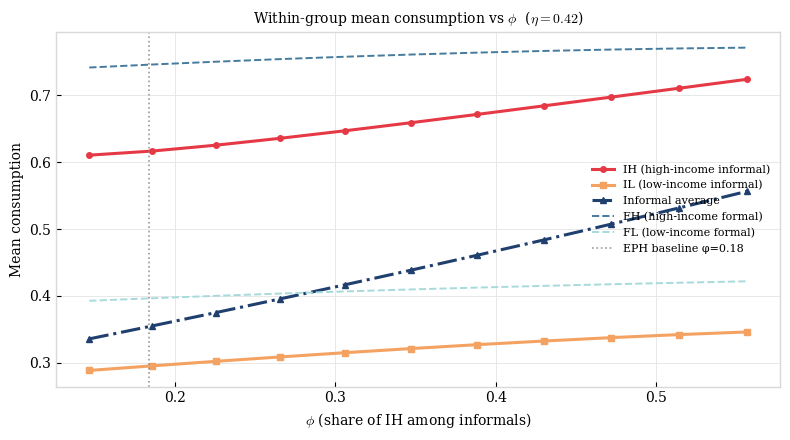

Figure saved: fig_phi_sweep_consumption_decomp.pdf


In [123]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(phi_eq_arr, df_phi["c_IH"].values,  color="#e63946", lw=lw, marker="o", ms=4,
        label="IH (high-income informal)")
ax.plot(phi_eq_arr, df_phi["c_IL"].values,  color="#f4a261", lw=lw, marker="s", ms=4,
        label="IL (low-income informal)")
ax.plot(phi_eq_arr, df_phi["c_inf_mean"].values, color=C4, lw=lw, ls="-.", marker="^", ms=4,
        label="Informal average")
ax.plot(phi_eq_arr, df_phi["c_FH"].values,  color="#457b9d", lw=1.4, ls="--",
        label="FH (high-income formal)")
ax.plot(phi_eq_arr, df_phi["c_FL"].values,  color="#a8dadc", lw=1.4, ls="--",
        label="FL (low-income formal)")

ax.axvline(phi_base, color="grey", lw=1.2, ls=":", alpha=0.8,
           label=f"EPH baseline φ={phi_base:.2f}")

ax.set_xlabel(r"$\phi$ (share of IH among informals)", fontsize=10)
ax.set_ylabel("Mean consumption", fontsize=10)
ax.set_title(r"Within-group mean consumption vs $\phi$  ($\eta=0.42$)", fontsize=10)
ax.legend(fontsize=8, loc="right")
ax.grid(True)
plt.tight_layout()
plt.savefig("fig_phi_sweep_consumption_decomp.pdf", bbox_inches="tight", dpi=150)
plt.show()
print("Figure saved: fig_phi_sweep_consumption_decomp.pdf")


## 9. Figure 3 — Borrowers Decomposition: IH vs IL

The mass of borrowers changes as φ rises due to the compositional shift: IH workers almost never borrow while IL workers frequently do. As the informal sector shifts toward IH, the aggregate borrowing mass changes even though individual borrowing rates within each group are nearly constant.


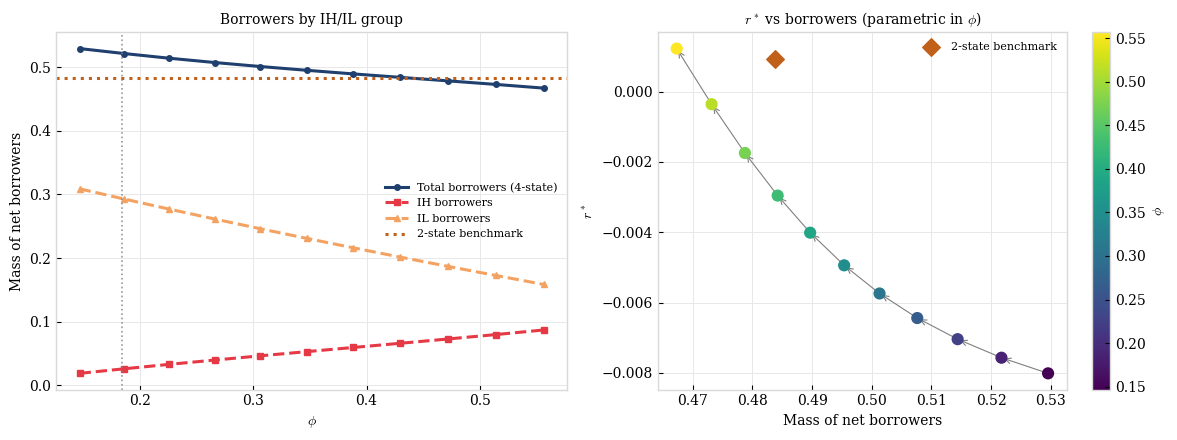

Figure saved: fig_phi_sweep_borrowers.pdf


In [124]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: total borrowers decomposed by IH / IL
ax = axes[0]
ax.plot(phi_eq_arr, df_phi["mass_borrowers"].values,     color=C4, lw=lw, marker="o", ms=4,
        label="Total borrowers (4-state)")
ax.plot(phi_eq_arr, df_phi["mass_borrowers_IH"].values,  color="#e63946", lw=lw, ls="--",
        marker="s", ms=4, label="IH borrowers")
ax.plot(phi_eq_arr, df_phi["mass_borrowers_IL"].values,  color="#f4a261", lw=lw, ls="--",
        marker="^", ms=4, label="IL borrowers")
ax.axhline(mass_b_2s, color=C2, lw=lw, ls=":", label="2-state benchmark")
ax.axvline(phi_base, color="grey", lw=1.2, ls=":", alpha=0.8)
ax.set_xlabel(r"$\phi$", fontsize=10)
ax.set_ylabel("Mass of net borrowers", fontsize=10)
ax.set_title("Borrowers by IH/IL group", fontsize=10)
ax.legend(fontsize=8); ax.grid(True)

# Right: r* vs mass of borrowers (parametric in φ)
ax = axes[1]
sc = ax.scatter(df_phi["mass_borrowers"].values, r_arr,
                c=phi_eq_arr, cmap="viridis", s=60, zorder=5)
for i in range(len(phi_eq_arr)-1):
    ax.annotate("", xy=(df_phi["mass_borrowers"].values[i+1], r_arr[i+1]),
                xytext=(df_phi["mass_borrowers"].values[i], r_arr[i]),
                arrowprops=dict(arrowstyle="->", color="grey", lw=0.8))
ax.scatter([mass_b_2s], [r2s], color=C2, marker="D", s=80, zorder=6,
           label="2-state benchmark")
plt.colorbar(sc, ax=ax, label=r"$\phi$")
ax.set_xlabel("Mass of net borrowers", fontsize=10)
ax.set_ylabel(r"$r^*$", fontsize=10)
ax.set_title(r"$r^*$ vs borrowers (parametric in $\phi$)", fontsize=10)
ax.legend(fontsize=8); ax.grid(True)

plt.tight_layout()
plt.savefig("fig_phi_sweep_borrowers.pdf", bbox_inches="tight", dpi=150)
plt.show()
print("Figure saved: fig_phi_sweep_borrowers.pdf")


## 10. Figure 4 — Consumption and Savings Policy Functions at Extreme φ Values

We plot the policy functions at three values of φ: the minimum, the EPH baseline, and the maximum. Each group's policy function is shown; the shift in the curves as φ changes reflects both the direct composition effect and the general equilibrium adjustment in r\*.


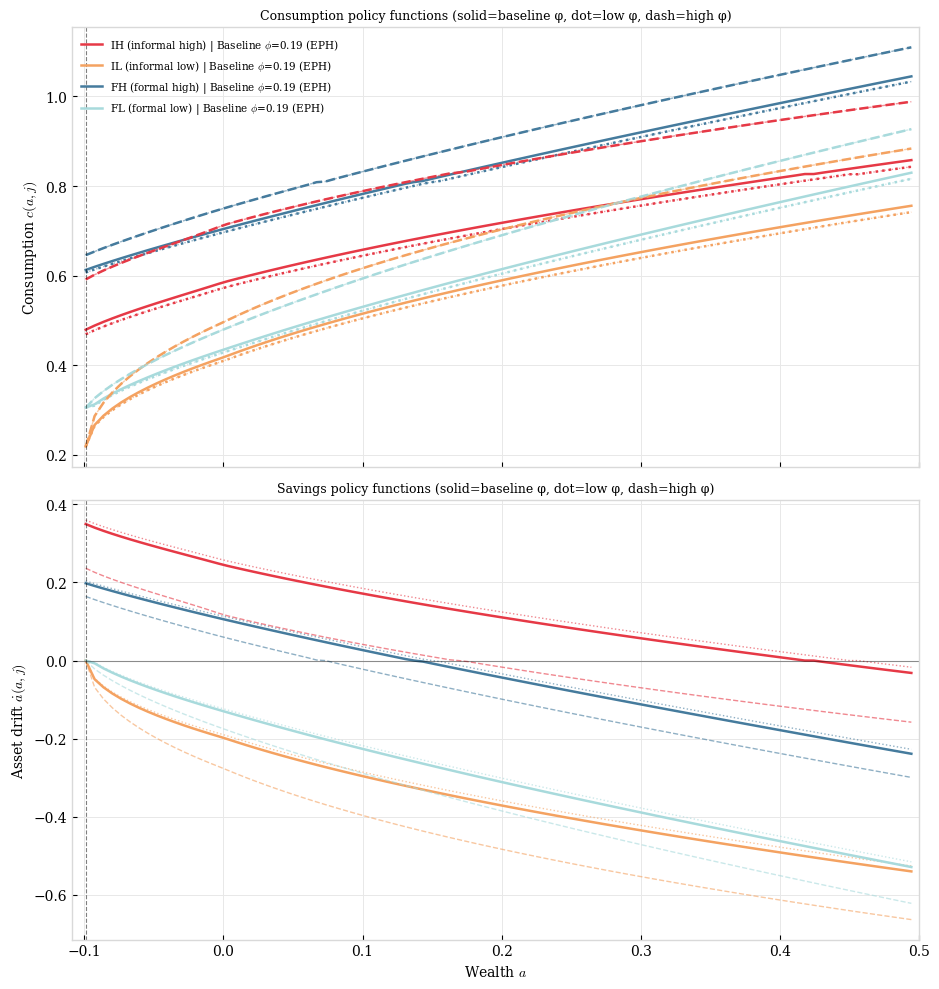

Figure saved: fig_phi_sweep_policy_functions_vertical.pdf


In [125]:
# Pick 3 φ values: low, baseline (nearest), high
idx_low  = 0
idx_base = int(np.argmin(np.abs(phi_eq_arr - phi_base)))
idx_high = len(phi_eq_arr) - 1

phi_labels  = {
    idx_low:  rf"Low $\phi$={phi_eq_arr[idx_low]:.2f}",
    idx_base: rf"Baseline $\phi$={phi_eq_arr[idx_base]:.2f} (EPH)",
    idx_high: rf"High $\phi$={phi_eq_arr[idx_high]:.2f}",
}
line_styles  = {idx_low: ":", idx_base: "-", idx_high: "--"}
colors_state = ["#e63946", "#f4a261", "#457b9d", "#a8dadc"]
state_names  = ["IH (informal high)", "IL (informal low)",
                "FH (formal high)",   "FL (formal low)"]

amax_plot = 0.5
amin_plot = base_params["amin"] - 0.01
a_plot    = base_params["a"]
mask      = a_plot <= amax_plot

fig, axes = plt.subplots(2, 1, figsize=(9.5, 10), sharex=True)

# ── Consumption ───────────────────────────────────────────────────────────────
ax = axes[0]
for idx, lbl in phi_labels.items():
    c_phi = results_phi[idx]["c"]
    for j, (col, sname) in enumerate(zip(colors_state, state_names)):
        ax.plot(a_plot[mask], c_phi[mask, j], color=col,
                ls=line_styles[idx], lw=1.8,
                label=f"{sname} | {lbl}" if idx == idx_base else None)
    if idx != idx_base:
        for j, col in enumerate(colors_state):
            ax.plot(a_plot[mask], c_phi[mask, j], color=col,
                    ls=line_styles[idx], lw=1.0, alpha=0.55)
ax.axvline(base_params["amin"], color="black", lw=0.8, ls="--", alpha=0.5)
ax.set_xlim([amin_plot, amax_plot])
ax.set_ylabel("Consumption $c(a,j)$", fontsize=10)
ax.set_title("Consumption policy functions (solid=baseline φ, dot=low φ, dash=high φ)", fontsize=9)
ax.legend(fontsize=7.5, loc="upper left")
ax.grid(True)

# ── Savings ───────────────────────────────────────────────────────────────────
ax = axes[1]
for idx, lbl in phi_labels.items():
    adot_phi = results_phi[idx]["adot"]
    for j, col in enumerate(colors_state):
        ax.plot(a_plot[mask], adot_phi[mask, j], color=col,
                ls=line_styles[idx],
                lw=(1.8 if idx == idx_base else 1.0),
                alpha=(1.0 if idx == idx_base else 0.6))
ax.axhline(0, color="black", lw=0.8, ls="-", alpha=0.4)
ax.axvline(base_params["amin"], color="black", lw=0.8, ls="--", alpha=0.5)
ax.set_xlim([amin_plot, amax_plot])
ax.set_xlabel("Wealth $a$", fontsize=10)
ax.set_ylabel(r"Asset drift $\dot{a}(a,j)$", fontsize=10)
ax.set_title("Savings policy functions (solid=baseline φ, dot=low φ, dash=high φ)", fontsize=9)
ax.grid(True)

plt.tight_layout()
plt.savefig("fig_phi_sweep_policy_functions_vertical.pdf", bbox_inches="tight", dpi=150)
plt.show()
print("Figure saved: fig_phi_sweep_policy_functions_vertical.pdf")


## 11. Summary Statistics Table

A compact table reporting the key macro statistics at selected φ values. Suitable for direct inclusion in the thesis.


In [126]:
selected = [0, idx_base, len(phi_eq_arr)-1]
rows = []
for i in selected:
    d = results_phi[i]
    rows.append({
        r"$\phi$ (target)":      f"{d['phi_target']:.3f}",
        r"$\phi$ (equilibrium)": f"{d['phi_eq']:.3f}",
        r"$\eta$ (equilibrium)": f"{d['eta_eq']:.4f}",
        r"$r^*$":                  f"{d['r_star']:.5f}",
        r"$\bar{c}_{IH}$":       f"{d['c_IH']:.4f}",
        r"$\bar{c}_{IL}$":       f"{d['c_IL']:.4f}",
        r"$\bar{c}_{inf}$":      f"{d['c_inf_mean']:.4f}",
        r"$\bar{c}_{for}$":      f"{d['c_for_mean']:.4f}",
        "Borrowers mass":          f"{d['mass_borrowers']:.4f}",
        "Gov. revenue":            f"{d['gov_rev']:.4f}",
    })

row_2s = {
    r"$\phi$ (target)":      "—",
    r"$\phi$ (equilibrium)": "—",
    r"$\eta$ (equilibrium)": f"{eta_arg:.4f}",
    r"$r^*$":                  f"{r2s:.5f}",
    r"$\bar{c}_{IH}$":       "—",
    r"$\bar{c}_{IL}$":       "—",
    r"$\bar{c}_{inf}$":      f"{c_inf_2s:.4f}",
    r"$\bar{c}_{for}$":      "—",
    "Borrowers mass":          f"{mass_b_2s:.4f}",
    "Gov. revenue":            "—",
}

summary_df = pd.DataFrame(rows, index=["Low φ", "Baseline φ (EPH)", "High φ"])
summary_df.loc["2-state benchmark"] = row_2s

print("\nSummary statistics across φ values (η = 0.42 fixed throughout):")
print(summary_df.to_string())



Summary statistics across φ values (η = 0.42 fixed throughout):
                  $\phi$ (target) $\phi$ (equilibrium) $\eta$ (equilibrium)     $r^*$ $\bar{c}_{IH}$ $\bar{c}_{IL}$ $\bar{c}_{inf}$ $\bar{c}_{for}$ Borrowers mass Gov. revenue
Low φ                       0.100                0.147               0.4200  -0.00801         0.6103         0.2888          0.3360          0.6331         0.5295       0.0789
Baseline φ (EPH)            0.150                0.186               0.4200  -0.00757         0.6165         0.2957          0.3553          0.6394         0.5217       0.0795
High φ                      0.600                0.557               0.4200   0.00122         0.7237         0.3463          0.5563          0.6796         0.4673       0.0838
2-state benchmark               —                    —               0.4200   0.00093              —              —          0.3932               —         0.4838            —


## 12. Interpretation and Thesis Narrative

### What the φ-sweep shows

The figures establish a result that **no two-state model can produce**: the macroeconomic equilibrium depends not just on how large the informal sector is (η), but on how it is composed internally (φ).

**Mean informal consumption rises with φ**: This is primarily a composition effect — as φ rises, the population weight shifts toward the higher-consuming IH group, raising the informal sector average even if individual consumption schedules are relatively stable.

**Mass of borrowers changes with φ**: IH workers almost never borrow. As they become a larger share of the informal sector, the aggregate borrowing mass changes accordingly. This is the precise composition mechanism behind the dynamics documented in Section 4.4 of the thesis.

**The 2-state model is blind to φ**: Its predictions are flat horizontal lines at every φ value. This flatness is not a feature — it is the blindspot. The two-state model averages over all compositions and reports a single number that corresponds to no particular φ and may substantially mischaracterise the actual economy.

### Why this matters for policy

Two economies with identical η = 0.42 but different φ will respond very differently to formalization reforms:

- In a **high-φ economy** (many IH workers), formalizing a marginal informal worker brings a high-income agent into the tax base, generating large fiscal dividends. The reform is likely near-revenue-neutral or better.
- In a **low-φ economy** (mostly IL workers), formalizing a marginal informal worker brings a low-income agent with little tax capacity. The fiscal dividend is small and the reform may require complementary financing.

The two-state model averages over these two scenarios and systematically misassigns the fiscal impact of formalization — a point that is invisible without explicitly tracking φ.
